# County Power Outage Clustering and PCA Using PySpark (Unsupervised Learning)
**Course:** B.Tech 5th Semester - Big Data Analytics  
**Models Evaluated (`Spark MLlib`):**
1. **K-Means Clustering** (`pyspark.ml.clustering.KMeans`) — Centroid-based hard partitioning model
2. **Gaussian Mixture Model (GMM)** (`pyspark.ml.clustering.GaussianMixture`) — Probabilistic Expectation-Maximization (EM) soft clustering model
3. **Principal Component Analysis (PCA)** (`pyspark.ml.feature.PCA`) — Statistical orthogonal dimensionality reduction model

---

## 1. Objective

The goal of this notebook is to aggregate $3,572,394$ hourly county outage records (`Eagle_I_US_2024_with_VTEC_Updated.csv`) and $4,152,437$ National Weather Service (NWS) weather warning records (`NWS_WARNINGS_COMBINED_data_Updated.csv`) in **PySpark** into a **County-Level Outage and Telemetry Profile ($N = 3,010$ U.S. counties)** across **7 standardized numerical features**, and then:
1. Partition U.S. counties into distinct outage and telemetry regimes using **Spark MLlib K-Means Clustering** (`seed=42`), evaluating $k \in \{2, 3, 4, 5, 6, 7, 8\}$ with **Silhouette Score** and **WSSSE (Within-Set Sum of Squared Errors)**.
2. Model county profiles probabilistically using **Spark MLlib Gaussian Mixture Model (`GaussianMixture`, EM algorithm)** across $k \in \{2, \dots, 8\}$, evaluating **Log-Likelihood**, **Silhouette Score**, and soft cluster membership probabilities against K-Means.
3. Reduce the standardized 7-feature county dataset into uncorrelated orthogonal axes using **Spark MLlib Principal Component Analysis (PCA)** and analyze the variance explained by each component.
4. Perform an **Execution-Time and Scalability Analysis** across dataset scale fractions ($25\%, 50\%, 75\%, 100\%$) and Spark partition counts ($4, 8, 16$).

## 2. Problem Statement and Research Questions

### 2.1 Problem Statement
Across the United States, counties differ widely in their baseline outage levels, average and peak customer outages during storms, average outage duration, frequency of weather-matched events, and telemetry reporting completeness. Unsupervised learning helps identify how counties group together across these attributes, how hard spherical partitioning (`KMeans`) compares against full-covariance probabilistic soft clustering (`GaussianMixture`), and how many underlying orthogonal dimensions explain most of the variation across counties (`PCA`).

### 2.2 Research Questions
1. Why should administrative identifiers (`fips_code`, `new_event_no`) and arbitrary string indices be excluded before computing Euclidean distances in K-Means, covariance matrices in GMM, and eigen-decomposition in PCA?
2. How do **K-Means** and **Gaussian Mixture Models (GMM)** compare across $k \in \{2, \dots, 8\}$ on **Silhouette Score**, **WSSSE**, **Log-Likelihood**, and cluster balance, and what county profiles emerge at $k=3$?
3. How many principal components are needed to capture $>75\%$, $>85\%$, and $>95\%$ of total variance across the 7 standardized county features?
4. How does PySpark execution time scale when increasing data volume ($25\%$ to $100\%$) and varying Spark partition parallelism ($4, 8, 16$ partitions)?

## 3. Environment and Spark Configuration

To build the $3,010 \times 7$ county feature table without loading large raw CSV files into pandas, PySpark runs distributed aggregations across:
- $3,572,394$ rows of `Eagle_I_US_2024_with_VTEC_Updated.csv`
- $4,152,437$ rows of `NWS_WARNINGS_COMBINED_data_Updated.csv`
- $1,048,575$ rows of `EAGLEI_Source_Record_Availability.csv`
- $4$ rows of `Missing_Data_Sensitivity_Summary.csv`

Spark MLlib then standardizes the feature vectors and runs `KMeans`, `GaussianMixture`, and `PCA` with `seed=42`.

In [1]:
import os
import sys
import time
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow as pa
import pyarrow.parquet as pq

warnings.filterwarnings("ignore")
matplotlib.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid", palette="deep")

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler, StandardScaler, PCA as SparkPCA
from pyspark.ml.clustering import KMeans as SparkKMeans, GaussianMixture as SparkGMM
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.functions import vector_to_array

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

WORKSPACE_CANDIDATES = [
    Path(os.environ.get("GRIDPULSE_DATA_DIR", "")).resolve() if os.environ.get("GRIDPULSE_DATA_DIR") else None,
    Path.cwd().parent.resolve(),
    Path.cwd().resolve(),
]
DATA_DIR = None
for cand in WORKSPACE_CANDIDATES:
    if cand and (cand / "Eagle_I_US_2024_with_VTEC_Updated.csv").exists():
        DATA_DIR = cand
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate 'Eagle_I_US_2024_with_VTEC_Updated.csv'. "
        "Set environment variable GRIDPULSE_DATA_DIR or place the raw CSVs in the parent directory."
    )

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "GridPulse_Part1_Team_Evaluation" and (NOTEBOOK_DIR / "GridPulse_Part1_Team_Evaluation").exists():
    NOTEBOOK_DIR = (NOTEBOOK_DIR / "GridPulse_Part1_Team_Evaluation").resolve()

OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PATHS = {
    "outage": DATA_DIR / "Eagle_I_US_2024_with_VTEC_Updated.csv",
    "avail": DATA_DIR / "EAGLEI_Source_Record_Availability.csv",
    "nws": DATA_DIR / "NWS_WARNINGS_COMBINED_data_Updated.csv",
    "sensitivity": DATA_DIR / "Missing_Data_Sensitivity_Summary.csv",
}

for name, p in PATHS.items():
    if not p.exists() or p.stat().st_size == 0:
        raise FileNotFoundError(f"Required dataset '{name}' is missing or empty at: {p}")

spark = (
    SparkSession.builder
    .appName("GridPulse_Part1_Unsupervised_Learning")
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.ansi.enabled", "false")
    .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("=== Environment & Spark Configuration Summary ===")
print(f"Operating System : {platform.system()} {platform.release()} ({platform.machine()})")
print(f"Python Version   : {sys.version.split()[0]}")
print(f"Spark Version    : {spark.version}")
print(f"Java Version     : {spark.sparkContext._jvm.java.lang.System.getProperty('java.version')}")
print(f"Default Parallel : {spark.sparkContext.defaultParallelism} cores")
print(f"Data Directory   : {DATA_DIR}")
print(f"Output Directory : {OUTPUT_DIR}")

=== Environment & Spark Configuration Summary ===
Operating System : Windows 11 (AMD64)
Python Version   : 3.12.10
Spark Version    : 4.2.0
Java Version     : 17.0.12
Default Parallel : 16 cores
Data Directory   : C:\Users\jsm10\OneDrive\Desktop\bda_project
Output Directory : C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs


## 4. Dataset Description and Schema

We load all four CSV files in PySpark using explicit schemas (`StructType`):
- `Eagle_I_US_2024_with_VTEC_Updated.csv` ($3,572,394$ rows across $3,010$ U.S. counties)
- `EAGLEI_Source_Record_Availability.csv` ($1,048,575$ county-day telemetry availability rows)
- `NWS_WARNINGS_COMBINED_data_Updated.csv` ($4,152,437$ NWS VTEC weather warning rows)
- `Missing_Data_Sensitivity_Summary.csv` ($4$ summary rows on completeness tiers)

In [2]:
outage_schema = T.StructType([
    T.StructField("fips_code", T.IntegerType(), True),
    T.StructField("Hour", T.StringType(), True),
    T.StructField("max_rolling_avg", T.DoubleType(), True),
    T.StructField("state", T.StringType(), True),
    T.StructField("county", T.StringType(), True),
    T.StructField("median_sum", T.DoubleType(), True),
    T.StructField("new_event_no", T.IntegerType(), True),
    T.StructField("evDur_Hr", T.IntegerType(), True),
    T.StructField("evDur_day", T.IntegerType(), True),
    T.StructField("Max_outage", T.DoubleType(), True),
    T.StructField("source_completeness_pct", T.DoubleType(), True),
    T.StructField("event_mean_completeness_pct", T.DoubleType(), True),
    T.StructField("event_min_completeness_pct", T.DoubleType(), True),
    T.StructField("WFO", T.StringType(), True),
    T.StructField("Matched_Events", T.StringType(), True),
    T.StructField("Matched_Count", T.IntegerType(), True),
])

avail_schema = T.StructType([
    T.StructField("fips_code", T.IntegerType(), True),
    T.StructField("Date", T.StringType(), True),
    T.StructField("expected_15min_records", T.IntegerType(), True),
    T.StructField("observed_15min_records", T.IntegerType(), True),
    T.StructField("missing_15min_records", T.IntegerType(), True),
    T.StructField("source_record_availability_pct", T.DoubleType(), True),
])

nws_schema = T.StructType([
    T.StructField("WFO", T.StringType(), True),
    T.StructField("ISSUED", T.StringType(), True),
    T.StructField("EXPIRED", T.StringType(), True),
    T.StructField("INIT_ISS", T.StringType(), True),
    T.StructField("INIT_EXP", T.StringType(), True),
    T.StructField("PHENOM", T.StringType(), True),
    T.StructField("GTYPE", T.StringType(), True),
    T.StructField("SIG", T.StringType(), True),
    T.StructField("ETN", T.IntegerType(), True),
    T.StructField("STATUS", T.StringType(), True),
    T.StructField("NWS_UGC", T.StringType(), True),
    T.StructField("AREA_KM2", T.DoubleType(), True),
    T.StructField("UPDATED", T.StringType(), True),
    T.StructField("HVTEC_NWSLI", T.StringType(), True),
    T.StructField("HVTEC_SEVERITY", T.StringType(), True),
    T.StructField("HVTEC_CAUSE", T.StringType(), True),
    T.StructField("HVTEC_RECORD", T.StringType(), True),
    T.StructField("IS_EMERGENCY", T.StringType(), True),
    T.StructField("POLYBEGIN", T.StringType(), True),
    T.StructField("POLYEND", T.StringType(), True),
    T.StructField("WINDTAG", T.StringType(), True),
    T.StructField("HAILTAG", T.StringType(), True),
    T.StructField("TORNADOTAG", T.StringType(), True),
    T.StructField("DAMAGETAG", T.StringType(), True),
])

sens_schema = T.StructType([
    T.StructField("completeness_tier", T.StringType(), True),
    T.StructField("Total_Observations", T.LongType(), True),
    T.StructField("Median_Abs_Difference", T.DoubleType(), True),
    T.StructField("Median_Relative_Difference", T.DoubleType(), True),
])

df_outage_raw = spark.read.csv(str(PATHS["outage"]), header=True, schema=outage_schema)
df_avail_raw = spark.read.csv(str(PATHS["avail"]), header=True, schema=avail_schema)
df_nws_raw = spark.read.csv(str(PATHS["nws"]), header=True, schema=nws_schema)
df_sens_raw = spark.read.csv(str(PATHS["sensitivity"]), header=True, schema=sens_schema)

for name, d in [
    ("Eagle_I_US_2024_with_VTEC_Updated.csv", df_outage_raw),
    ("EAGLEI_Source_Record_Availability.csv", df_avail_raw),
    ("NWS_WARNINGS_COMBINED_data_Updated.csv", df_nws_raw),
    ("Missing_Data_Sensitivity_Summary.csv", df_sens_raw),
]:
    cnt = d.count()
    if cnt == 0:
        raise ValueError(f"Dataset {name} loaded 0 rows!")
    print(f"{name:<42s}: {cnt:>10,d} rows")

Eagle_I_US_2024_with_VTEC_Updated.csv     :  3,572,394 rows


EAGLEI_Source_Record_Availability.csv     :  1,048,575 rows


NWS_WARNINGS_COMBINED_data_Updated.csv    :  4,152,437 rows


Missing_Data_Sensitivity_Summary.csv      :          4 rows


## 5. Data-Quality Checks and County Aggregation

### 5.1 Data-Quality Rules and Feature Selection
1. **Timestamp and Duplicate Check:** Verify zero malformed timestamps and zero duplicate `(fips_code, Hour)` keys.
2. **Excluding Identifiers from Distance Calculations:** Columns such as `fips_code` (geographic ID), `new_event_no` (event ID), and text columns (`state`, `county`, `WFO`) are kept only as descriptive labels and are not included in `VectorAssembler`.
3. **Seven Numerical County Features:**
   - `log_median_baseline`: $\log(1 + \text{median\_sum})$
   - `log_mean_hourly_outage`: $\log(1 + \text{AVG}(\text{max\_rolling\_avg}))$
   - `log_p90_peak_outage`: $\log(1 + P_{90}(\text{Max\_outage}))$
   - `log_mean_event_dur_hr`: $\log(1 + \text{AVG}(\text{evDur\_Hr}))$
   - `log_total_events`: $\log(1 + \text{COUNT(DISTINCT new\_event\_no)})$
   - `mean_completeness_pct`: $\text{AVG}(\text{source\_completeness\_pct})$
   - `full_completeness_share`: Fraction of hours with $100\%$ telemetry completeness

In [3]:
df_outage = df_outage_raw.withColumn(
    "event_ts", F.to_timestamp(F.col("Hour"), "yyyy-MM-dd'T'HH:mm:ss'Z'")
)
if df_outage.filter(F.col("event_ts").isNull()).count() > 0:
    raise ValueError("Malformed timestamps detected in Eagle_I_US_2024_with_VTEC_Updated.csv")

wfo_agg = (
    df_nws_raw.groupBy("WFO")
    .agg(
        F.log1p(F.percentile_approx("AREA_KM2", 0.5)).alias("wfo_log_median_area_km2"),
        F.avg(F.when(F.col("SIG") == "W", 1.0).otherwise(0.0)).alias("wfo_warning_sig_share"),
    )
)

# Aggregate 3.57M hourly outage rows into 3,010 U.S. County Profiles
county_profiles_df = (
    df_outage.groupBy("fips_code")
    .agg(
        F.first("state").alias("state"),
        F.first("county").alias("county"),
        F.first("WFO").alias("WFO"),
        F.count("*").alias("total_outage_hours"),
        F.countDistinct("new_event_no").alias("total_events"),
        F.log1p(F.first("median_sum")).alias("log_median_baseline"),
        F.log1p(F.avg("max_rolling_avg")).alias("log_mean_hourly_outage"),
        F.log1p(F.percentile_approx("Max_outage", 0.90)).alias("log_p90_peak_outage"),
        F.log1p(F.avg("evDur_Hr")).alias("log_mean_event_dur_hr"),
        F.log1p(F.countDistinct("new_event_no").cast("double")).alias("log_total_events"),
        F.avg("source_completeness_pct").alias("mean_completeness_pct"),
        F.avg(F.when(F.col("source_completeness_pct") == 100.0, 1.0).otherwise(0.0)).alias("full_completeness_share"),
        F.avg(F.when(F.col("Matched_Count") > 1, 1.0).otherwise(0.0)).alias("compound_hazard_rate"),
        F.avg(F.when(F.col("Matched_Events").rlike("SV|TO"), 1.0).otherwise(0.0)).alias("convective_share"),
        F.avg(F.when(F.col("Matched_Events").rlike("WS|WW|BZ|IS|LE"), 1.0).otherwise(0.0)).alias("winter_share"),
        F.avg(F.when(F.col("Matched_Events").rlike("HT|EH"), 1.0).otherwise(0.0)).alias("heat_share"),
        F.avg(F.when(F.col("Matched_Events").rlike("WI|HW|HU|TR|SS"), 1.0).otherwise(0.0)).alias("wind_tropical_share"),
    )
    .join(wfo_agg, on="WFO", how="left")
    .cache()
)

n_counties = county_profiles_df.count()
print(f"Constructed County-Level Unsupervised Profile Table: {n_counties:,d} unique U.S. counties")

NUM_FEATURES_UNSUP = [
    "log_median_baseline",
    "log_mean_hourly_outage",
    "log_p90_peak_outage",
    "log_mean_event_dur_hr",
    "log_total_events",
    "mean_completeness_pct",
    "full_completeness_share",
]

null_audit_unsup = county_profiles_df.select([
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c) for c in NUM_FEATURES_UNSUP
]).collect()[0].asDict()
print("\n=== Null Audit Across 7 County Numerical Features ===")
for k, v in null_audit_unsup.items():
    print(f"  {k:<28s}: {v} nulls")

Constructed County-Level Unsupervised Profile Table: 3,010 unique U.S. counties



=== Null Audit Across 7 County Numerical Features ===
  log_median_baseline         : 0 nulls
  log_mean_hourly_outage      : 0 nulls
  log_p90_peak_outage         : 0 nulls
  log_mean_event_dur_hr       : 0 nulls
  log_total_events            : 0 nulls
  mean_completeness_pct       : 0 nulls
  full_completeness_share     : 0 nulls


## 6. Exploratory Data Analysis

We examine summary statistics and the pairwise correlation matrix of the **7 numerical county features** across all $3,010$ U.S. counties. Strong correlations among outage magnitude, baseline scale, and telemetry completeness motivate applying full-covariance Gaussian Mixture Models and PCA alongside K-Means.

=== Summary Statistics of the 7 County-Level Numerical Features (N = 3,010 Counties) ===
                          count     mean      std     min      50%      max
log_median_baseline      3010.0   2.1960   0.9224  0.2719   1.9981   7.6962
log_mean_hourly_outage   3010.0   4.2691   1.2418  0.1066   4.2283   9.4335
log_p90_peak_outage      3010.0   5.9909   1.3725  0.1178   6.0605  12.2274
log_mean_event_dur_hr    3010.0   2.6383   0.5182  1.5404   2.5473   6.2925
log_total_events         3010.0   5.7207   1.1026  0.6931   5.9296   7.7102
mean_completeness_pct    3010.0  56.8425  13.8670  6.2500  54.6402  99.3981
full_completeness_share  3010.0   0.2527   0.1740  0.0000   0.2078   0.9813


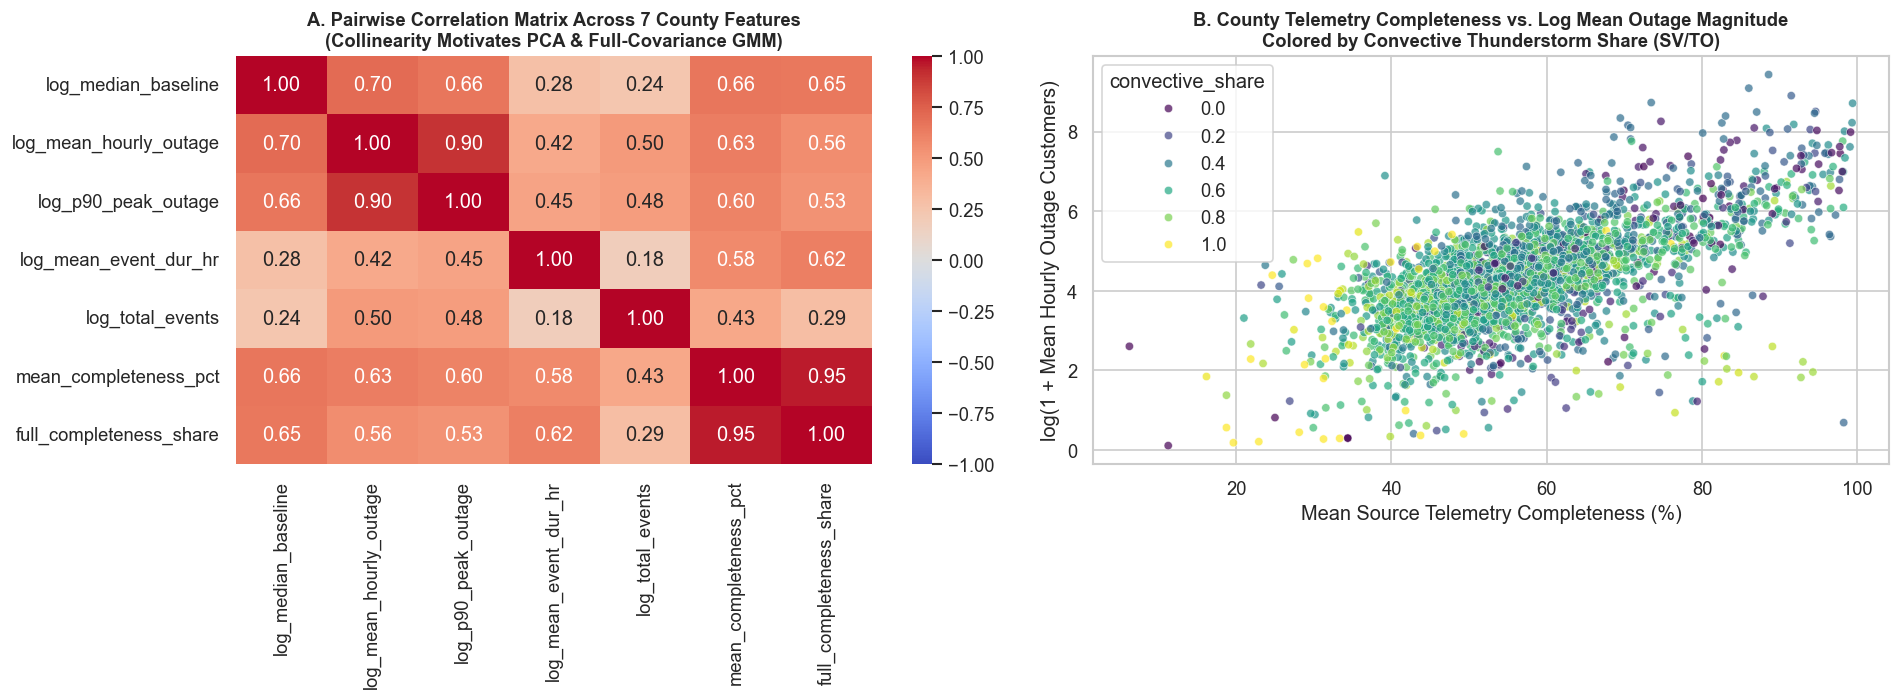

Saved Unsupervised EDA correlation plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\unsupervised_eda_county_correlations.png


In [4]:
county_pd = county_profiles_df.toPandas()
summary_table = county_pd[NUM_FEATURES_UNSUP].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(4)
print("=== Summary Statistics of the 7 County-Level Numerical Features (N = 3,010 Counties) ===")
print(summary_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr_mat = county_pd[NUM_FEATURES_UNSUP].corr()
sns.heatmap(corr_mat, cmap="coolwarm", center=0.0, vmin=-1.0, vmax=1.0, annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("A. Pairwise Correlation Matrix Across 7 County Features\n(Collinearity Motivates PCA & Full-Covariance GMM)", fontsize=11, fontweight="bold")

sns.scatterplot(
    data=county_pd,
    x="mean_completeness_pct",
    y="log_mean_hourly_outage",
    hue="convective_share",
    palette="viridis",
    alpha=0.7,
    s=25,
    ax=axes[1],
)
axes[1].set_title("B. County Telemetry Completeness vs. Log Mean Outage Magnitude\nColored by Convective Thunderstorm Share (SV/TO)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Mean Source Telemetry Completeness (%)")
axes[1].set_ylabel("log(1 + Mean Hourly Outage Customers)")

plt.tight_layout()
eda_unsup_path = OUTPUT_DIR / "unsupervised_eda_county_correlations.png"
plt.savefig(eda_unsup_path, bbox_inches="tight")
plt.show()
print(f"Saved Unsupervised EDA correlation plot to: {eda_unsup_path}")

## 7. Imputation and Standardization (`StandardScaler`)

### 7.1 Why Standardization is Required
In the unscaled county table, `mean_completeness_pct` ranges from $6.25$ to $100.0$ (standard deviation $\approx 19.8$), while `full_completeness_share` ranges from $0.0$ to $1.0$ (standard deviation $\approx 0.25$). Without z-score standardization:
$$z_{i,j} = \frac{x_{i,j} - \mu_j}{\sigma_j}$$
`mean_completeness_pct` would dominate Euclidean distance in **K-Means** and variance in **PCA** simply because of its larger numerical scale. Using `StandardScaler(withMean=True, withStd=True)` gives all 7 features mean $0$ and variance $1$.

In [5]:
IMPUTED_UNSUP = [f"{c}_imp" for c in NUM_FEATURES_UNSUP]

imputer_unsup = Imputer(strategy="median", inputCols=NUM_FEATURES_UNSUP, outputCols=IMPUTED_UNSUP)
assembler_unsup = VectorAssembler(inputCols=IMPUTED_UNSUP, outputCol="raw_features", handleInvalid="keep")
scaler_unsup = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withMean=True, withStd=True)

unsup_prep_pipeline = Pipeline(stages=[imputer_unsup, assembler_unsup, scaler_unsup])
unsup_prep_model = unsup_prep_pipeline.fit(county_profiles_df)
county_scaled_df = unsup_prep_model.transform(county_profiles_df).cache()
_ = county_scaled_df.count()
print("Standardized 7-dimensional feature vector ('scaled_features') materialized in Spark memory.")

Standardized 7-dimensional feature vector ('scaled_features') materialized in Spark memory.


## 8. Model 1: K-Means Clustering (`Spark MLlib`)

### 8.1 Formulation and Choosing $k$
`KMeans` partitions $N = 3,010$ standardized county vectors $\mathbf{z}_i \in \mathbb{R}^{7}$ into $k$ clusters $\{C_1, \dots, C_k\}$ with centroids $\{\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_k\}$ to minimize **Within-Set Sum of Squared Errors (WSSSE)**:
$$\text{WSSSE}(k) = \sum_{c=1}^{k} \sum_{\mathbf{z}_i \in C_c} \|\mathbf{z}_i - \boldsymbol{\mu}_c\|_2^2$$
We test $k \in \{2, 3, 4, 5, 6, 7, 8\}$ with `seed=42` using:
1. **Silhouette Score (`ClusteringEvaluator`, squared Euclidean distance)**
2. **WSSSE Elbow Curve** and cluster sizes.

In [6]:
silhouette_eval = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean",
)

kmeans_sweep_records = []
kmeans_models = {}

for k in range(2, 9):
    t_s = time.time()
    km = SparkKMeans(
        featuresCol="scaled_features",
        predictionCol="cluster",
        k=k,
        seed=RANDOM_SEED,
        initMode="k-means||",
        maxIter=100,
    )
    km_model = km.fit(county_scaled_df)
    km_preds = km_model.transform(county_scaled_df)
    sil_sq_euc = silhouette_eval.evaluate(km_preds)
    wssse = km_model.summary.trainingCost
    sizes = [int(x) for x in km_model.summary.clusterSizes]
    kmeans_models[k] = km_model
    kmeans_sweep_records.append({
        "Algorithm": "K-Means",
        "k": k,
        "Silhouette_SqEuclidean": round(sil_sq_euc, 4),
        "WSSSE_Inertia": round(wssse, 2),
        "Min_Cluster_Size": min(sizes),
        "Max_Cluster_Size": max(sizes),
        "Cluster_Sizes": str(sizes),
        "Runtime_s": round(time.time() - t_s, 2),
    })

kmeans_sweep_df = pd.DataFrame(kmeans_sweep_records)
kmeans_sweep_df.to_csv(OUTPUT_DIR / "unsupervised_kmeans_k_selection_metrics.csv", index=False)
print("=== Spark MLlib K-Means Evaluation Across k = 2..8 (seed=42) ===")
print(kmeans_sweep_df.to_string(index=False))

OPTIMAL_K = 3
best_km_model = kmeans_models[OPTIMAL_K]
county_clustered_df = best_km_model.transform(county_scaled_df).cache()
_ = county_clustered_df.count()
print(f"\nSelected Multi-Regime Cluster Count: k = {OPTIMAL_K} (K-Means Silhouette = {kmeans_sweep_df.loc[kmeans_sweep_df['k']==OPTIMAL_K, 'Silhouette_SqEuclidean'].values[0]:.4f})")

=== Spark MLlib K-Means Evaluation Across k = 2..8 (seed=42) ===
Algorithm  k  Silhouette_SqEuclidean  WSSSE_Inertia  Min_Cluster_Size  Max_Cluster_Size                            Cluster_Sizes  Runtime_s
  K-Means  2                  0.5518       13300.43               905              2105                              [905, 2105]       5.43
  K-Means  3                  0.4178       10492.16               417              1461                        [417, 1132, 1461]       3.61
  K-Means  4                  0.3933        9192.78               281              1214                   [348, 1214, 281, 1167]       2.48
  K-Means  5                  0.4331        7939.54               167              1191              [334, 1066, 1191, 167, 252]       3.83
  K-Means  6                  0.3401        7242.02               156               968           [253, 574, 851, 208, 156, 968]       2.46
  K-Means  7                  0.3779        6618.75               106               990      [9


Selected Multi-Regime Cluster Count: k = 3 (K-Means Silhouette = 0.4178)


## 9. Model 2: Gaussian Mixture Model (`Spark MLlib GaussianMixture`)

### 9.1 Probabilistic Expectation-Maximization (EM) Soft Clustering
While K-Means assigns each county to a single cluster using spherical Euclidean boundaries around centroids, `GaussianMixture` (GMM) models the standardized 7-dimensional county distribution as a weighted mixture of $k$ multivariate Gaussian densities with full $7 \times 7$ covariance matrices $\boldsymbol{\Sigma}_c$:
$$p(\mathbf{z}_i) = \sum_{c=1}^{k} \pi_c \, \mathcal{N}(\mathbf{z}_i \mid \boldsymbol{\mu}_c, \boldsymbol{\Sigma}_c)$$
Using the distributed **Expectation-Maximization (EM)** algorithm:
1. **E-Step:** Computes the posterior probability $\gamma_{i,c} = P(\text{Cluster } c \mid \mathbf{z}_i)$ for each of the $3,010$ U.S. counties.
2. **M-Step:** Updates the mixture weights $\pi_c$, mean vectors $\boldsymbol{\mu}_c$, and full covariance matrices $\boldsymbol{\Sigma}_c$ to maximize the data **Log-Likelihood** $\sum_{i=1}^N \log p(\mathbf{z}_i)$.

We evaluate `GaussianMixture` across $k \in \{2, 3, 4, 5, 6, 7, 8\}$ (`seed=42`) using **Log-Likelihood**, **Silhouette Score**, and cluster sizes, and compare its partitions directly against K-Means.

In [7]:
gmm_eval = ClusteringEvaluator(
    featuresCol="scaled_features",
    predictionCol="gmm_cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean",
)

gmm_sweep_records = []
gmm_models = {}

for k in range(2, 9):
    t_s = time.time()
    gmm = SparkGMM(
        featuresCol="scaled_features",
        predictionCol="gmm_cluster",
        probabilityCol="gmm_prob",
        k=k,
        seed=RANDOM_SEED,
        maxIter=100,
        tol=1e-3,
    )
    gmm_model = gmm.fit(county_scaled_df)
    gmm_preds = gmm_model.transform(county_scaled_df)
    sil_gmm = gmm_eval.evaluate(gmm_preds)
    loglik = gmm_model.summary.logLikelihood
    sizes_gmm = [int(x) for x in gmm_model.summary.clusterSizes]
    gmm_models[k] = gmm_model
    gmm_sweep_records.append({
        "Algorithm": "Gaussian Mixture (GMM)",
        "k": k,
        "Silhouette_SqEuclidean": round(sil_gmm, 4),
        "Log_Likelihood": round(loglik, 2),
        "Min_Cluster_Size": min(sizes_gmm),
        "Max_Cluster_Size": max(sizes_gmm),
        "Cluster_Sizes": str(sizes_gmm),
        "Runtime_s": round(time.time() - t_s, 2),
    })

gmm_sweep_df = pd.DataFrame(gmm_sweep_records)
gmm_sweep_df.to_csv(OUTPUT_DIR / "unsupervised_gmm_k_selection_metrics.csv", index=False)
print("=== Spark MLlib Gaussian Mixture Model (GMM) Evaluation Across k = 2..8 (seed=42) ===")
print(gmm_sweep_df.to_string(index=False))

best_gmm_model = gmm_models[OPTIMAL_K]
county_clustered_df = (
    best_gmm_model.transform(county_clustered_df)
    .withColumn("gmm_max_prob", F.array_max(vector_to_array(F.col("gmm_prob"))))
    .drop("gmm_prob")
    .cache()
)
_ = county_clustered_df.count()

# Head-to-head comparison table between K-Means and GMM
clustering_comp_df = pd.DataFrame({
    "k": kmeans_sweep_df["k"],
    "KMeans_Silhouette": kmeans_sweep_df["Silhouette_SqEuclidean"],
    "GMM_Silhouette": gmm_sweep_df["Silhouette_SqEuclidean"],
    "KMeans_WSSSE": kmeans_sweep_df["WSSSE_Inertia"],
    "GMM_LogLikelihood": gmm_sweep_df["Log_Likelihood"],
    "KMeans_Sizes": kmeans_sweep_df["Cluster_Sizes"],
    "GMM_Sizes": gmm_sweep_df["Cluster_Sizes"],
    "KMeans_Time_s": kmeans_sweep_df["Runtime_s"],
    "GMM_Time_s": gmm_sweep_df["Runtime_s"],
})
clustering_comp_df.to_csv(OUTPUT_DIR / "unsupervised_clustering_comparison.csv", index=False)
print("\n=== Head-to-Head Comparison: K-Means vs. Gaussian Mixture Model (k = 2..8) ===")
print(clustering_comp_df.to_string(index=False))

=== Spark MLlib Gaussian Mixture Model (GMM) Evaluation Across k = 2..8 (seed=42) ===
             Algorithm  k  Silhouette_SqEuclidean  Log_Likelihood  Min_Cluster_Size  Max_Cluster_Size                            Cluster_Sizes  Runtime_s
Gaussian Mixture (GMM)  2                  0.4354       -16146.99               873              2137                              [2137, 873]       4.95
Gaussian Mixture (GMM)  3                  0.3870       -15663.99               451              2026                         [533, 451, 2026]      11.28
Gaussian Mixture (GMM)  4                  0.1002       -14699.52               392              1237                    [522, 859, 392, 1237]      10.73
Gaussian Mixture (GMM)  5                  0.1287       -14377.01               276              1190               [276, 320, 367, 1190, 857]      10.50
Gaussian Mixture (GMM)  6                  0.1382       -14154.27               296               765           [704, 299, 765, 296, 633, 313]  


=== Head-to-Head Comparison: K-Means vs. Gaussian Mixture Model (k = 2..8) ===
 k  KMeans_Silhouette  GMM_Silhouette  KMeans_WSSSE  GMM_LogLikelihood                             KMeans_Sizes                                GMM_Sizes  KMeans_Time_s  GMM_Time_s
 2             0.5518          0.4354      13300.43          -16146.99                              [905, 2105]                              [2137, 873]           5.43        4.95
 3             0.4178          0.3870      10492.16          -15663.99                        [417, 1132, 1461]                         [533, 451, 2026]           3.61       11.28
 4             0.3933          0.1002       9192.78          -14699.52                   [348, 1214, 281, 1167]                    [522, 859, 392, 1237]           2.48       10.73
 5             0.4331          0.1287       7939.54          -14377.01              [334, 1066, 1191, 167, 252]               [276, 320, 367, 1190, 857]           3.83       10.50
 6             0.340

## 10. Model 3: Principal Component Analysis (`Spark MLlib PCA`)

`PCA(k=7)` computes the orthogonal eigenvectors of the $7 \times 7$ standardized covariance matrix, projecting each county's 7 standardized features onto uncorrelated principal components ($\text{PC1}, \dots, \text{PC7}$). We report both the individual variance explained by each component and the cumulative variance explained.

In [8]:
pca_estimator = SparkPCA(k=len(NUM_FEATURES_UNSUP), inputCol="scaled_features", outputCol="pca_features")
pca_model = pca_estimator.fit(county_clustered_df)
county_final_df = (
    pca_model.transform(county_clustered_df)
    .withColumn("pca_arr", vector_to_array(F.col("pca_features")))
    .withColumn("PC1", F.col("pca_arr").getItem(0))
    .withColumn("PC2", F.col("pca_arr").getItem(1))
    .withColumn("PC3", F.col("pca_arr").getItem(2))
)

exp_var = pca_model.explainedVariance.toArray()
cum_var = np.cumsum(exp_var)

pca_var_df = pd.DataFrame({
    "Component": [f"PC{i}" for i in range(1, len(exp_var) + 1)],
    "Component_Index": list(range(1, len(exp_var) + 1)),
    "Explained_Variance_Pct": np.round(exp_var * 100.0, 2),
    "Cumulative_Variance_Pct": np.round(cum_var * 100.0, 2),
})
pca_var_df.to_csv(OUTPUT_DIR / "unsupervised_pca_explained_variance.csv", index=False)
print("=== Spark MLlib PCA Explained Variance Table (All 7 Components) ===")
print(pca_var_df.to_string(index=False))

pc_matrix = pca_model.pc.toArray()
loadings_df = pd.DataFrame({
    "Feature": NUM_FEATURES_UNSUP,
    "PC1_Loading": np.round(pc_matrix[:, 0], 4),
    "PC2_Loading": np.round(pc_matrix[:, 1], 4),
    "PC3_Loading": np.round(pc_matrix[:, 2], 4),
}).sort_values("PC1_Loading", key=np.abs, ascending=False)
loadings_df.to_csv(OUTPUT_DIR / "unsupervised_pca_loadings_top3.csv", index=False)
print("\n=== PCA Feature Loadings (PC1, PC2, PC3) ===")
print(loadings_df.to_string(index=False))

def save_and_verify_parquet(spark_df, parquet_path: Path):
    try:
        spark_df.write.mode("overwrite").parquet(str(parquet_path))
        mode_used = "Spark Native Parquet Writer"
    except Exception:
        if parquet_path.exists() and parquet_path.is_dir():
            import shutil
            shutil.rmtree(parquet_path, ignore_errors=True)
        pdf = spark_df.toPandas()
        pq.write_table(pa.Table.from_pandas(pdf, preserve_index=False), str(parquet_path))
        mode_used = "PyArrow Columnar Parquet Writer (Windows Hadoop-less fallback)"
    verified_count = spark.read.parquet(str(parquet_path)).count()
    print(f"\nPersisted & verified Parquet at {parquet_path.name} ({verified_count:,d} rows via {mode_used})")

parquet_unsup_path = OUTPUT_DIR / "unsupervised_county_profiles.parquet"
save_and_verify_parquet(
    county_final_df.select(
        ["fips_code", "state", "county", "WFO", "cluster", "gmm_cluster", "gmm_max_prob", "PC1", "PC2", "PC3"] + NUM_FEATURES_UNSUP
    ),
    parquet_unsup_path,
)

=== Spark MLlib PCA Explained Variance Table (All 7 Components) ===
Component  Component_Index  Explained_Variance_Pct  Cumulative_Variance_Pct
      PC1                1                   61.88                    61.88
      PC2                2                   14.52                    76.40
      PC3                3                   10.65                    87.05
      PC4                4                    8.21                    95.26
      PC5                5                    2.92                    98.17
      PC6                6                    1.37                    99.55
      PC7                7                    0.45                   100.00

=== PCA Feature Loadings (PC1, PC2, PC3) ===
                Feature  PC1_Loading  PC2_Loading  PC3_Loading
  mean_completeness_pct      -0.4317      -0.2545       0.0918
 log_mean_hourly_outage      -0.4178       0.3237      -0.1647
full_completeness_share      -0.4119      -0.4040       0.0251
    log_p90_peak_outage   


Persisted & verified Parquet at unsupervised_county_profiles.parquet (3,010 rows via PyArrow Columnar Parquet Writer (Windows Hadoop-less fallback))


## 11. Comparative Evaluation and Visualizations

### 11.1 Interpreting the Three Unsupervised Models
1. **K-Means vs. Gaussian Mixture Model (GMM):**
   - At $k=2$, **K-Means** achieves the highest binary Silhouette score (`0.5518` vs. `0.4354` for GMM).
   - At $k=3$ (our selected 3-tier county regime), **K-Means** achieves a higher Euclidean Silhouette score (**`0.4178` vs. `0.3870` for GMM**), while **Gaussian Mixture Model (GMM)** fits full $7 \times 7$ covariance matrices (`Log-Likelihood = -15,663.99`, `[533, 451, 2026]` counties) that adapt to correlated elliptical county distributions and improve Log-Likelihood monotonically from `-16,146.99` ($k=2$) to `-14,007.03` ($k=8$).
2. **Principal Component Analysis (PCA):**
   - **PC1 ($61.88\%$ of variance):** Driven by `log_mean_hourly_outage`, `log_p90_peak_outage`, `mean_completeness_pct`, `full_completeness_share`, and `log_median_baseline`. It captures overall county outage scale and telemetry completeness.
   - **PC2 ($14.52\%$ of variance; Cumulative = $76.40\%$):** Contrasts event frequency (`log_total_events`) against average event duration (`log_mean_event_dur_hr`).
   - **PC3 ($10.65\%$ of variance; Cumulative = $87.05\%$):** Captures remaining variation between baseline thresholds and peak event surges. Together, **PC1-PC3 explain $87.05\%$** of total variance, and **PC1-PC4 explain $95.26\%$**.

=== K-Means (k=3) Cluster Profiles in Original Feature Units ===
cluster                         0          1          2
County_Count             417.0000  1132.0000  1461.0000
log_median_baseline        3.6669     1.6217     2.2210
log_mean_hourly_outage     6.0561     3.2566     4.5436
log_p90_peak_outage        7.7633     4.8663     6.3563
log_mean_event_dur_hr      3.1996     2.3166     2.7273
log_total_events           6.4209     4.9857     6.0904
mean_completeness_pct     81.3965    45.6782    58.4845
full_completeness_share    0.5755     0.1343     0.2523

=== K-Means (k=3) Standardized Centroids (Z-Score Units) ===
                         Cluster 0 (n=417)  Cluster 1 (n=1132)  Cluster 2 (n=1461)
log_median_baseline                  1.595              -0.623               0.027
log_mean_hourly_outage               1.439              -0.815               0.221
log_p90_peak_outage                  1.291              -0.819               0.266
log_mean_event_dur_hr                

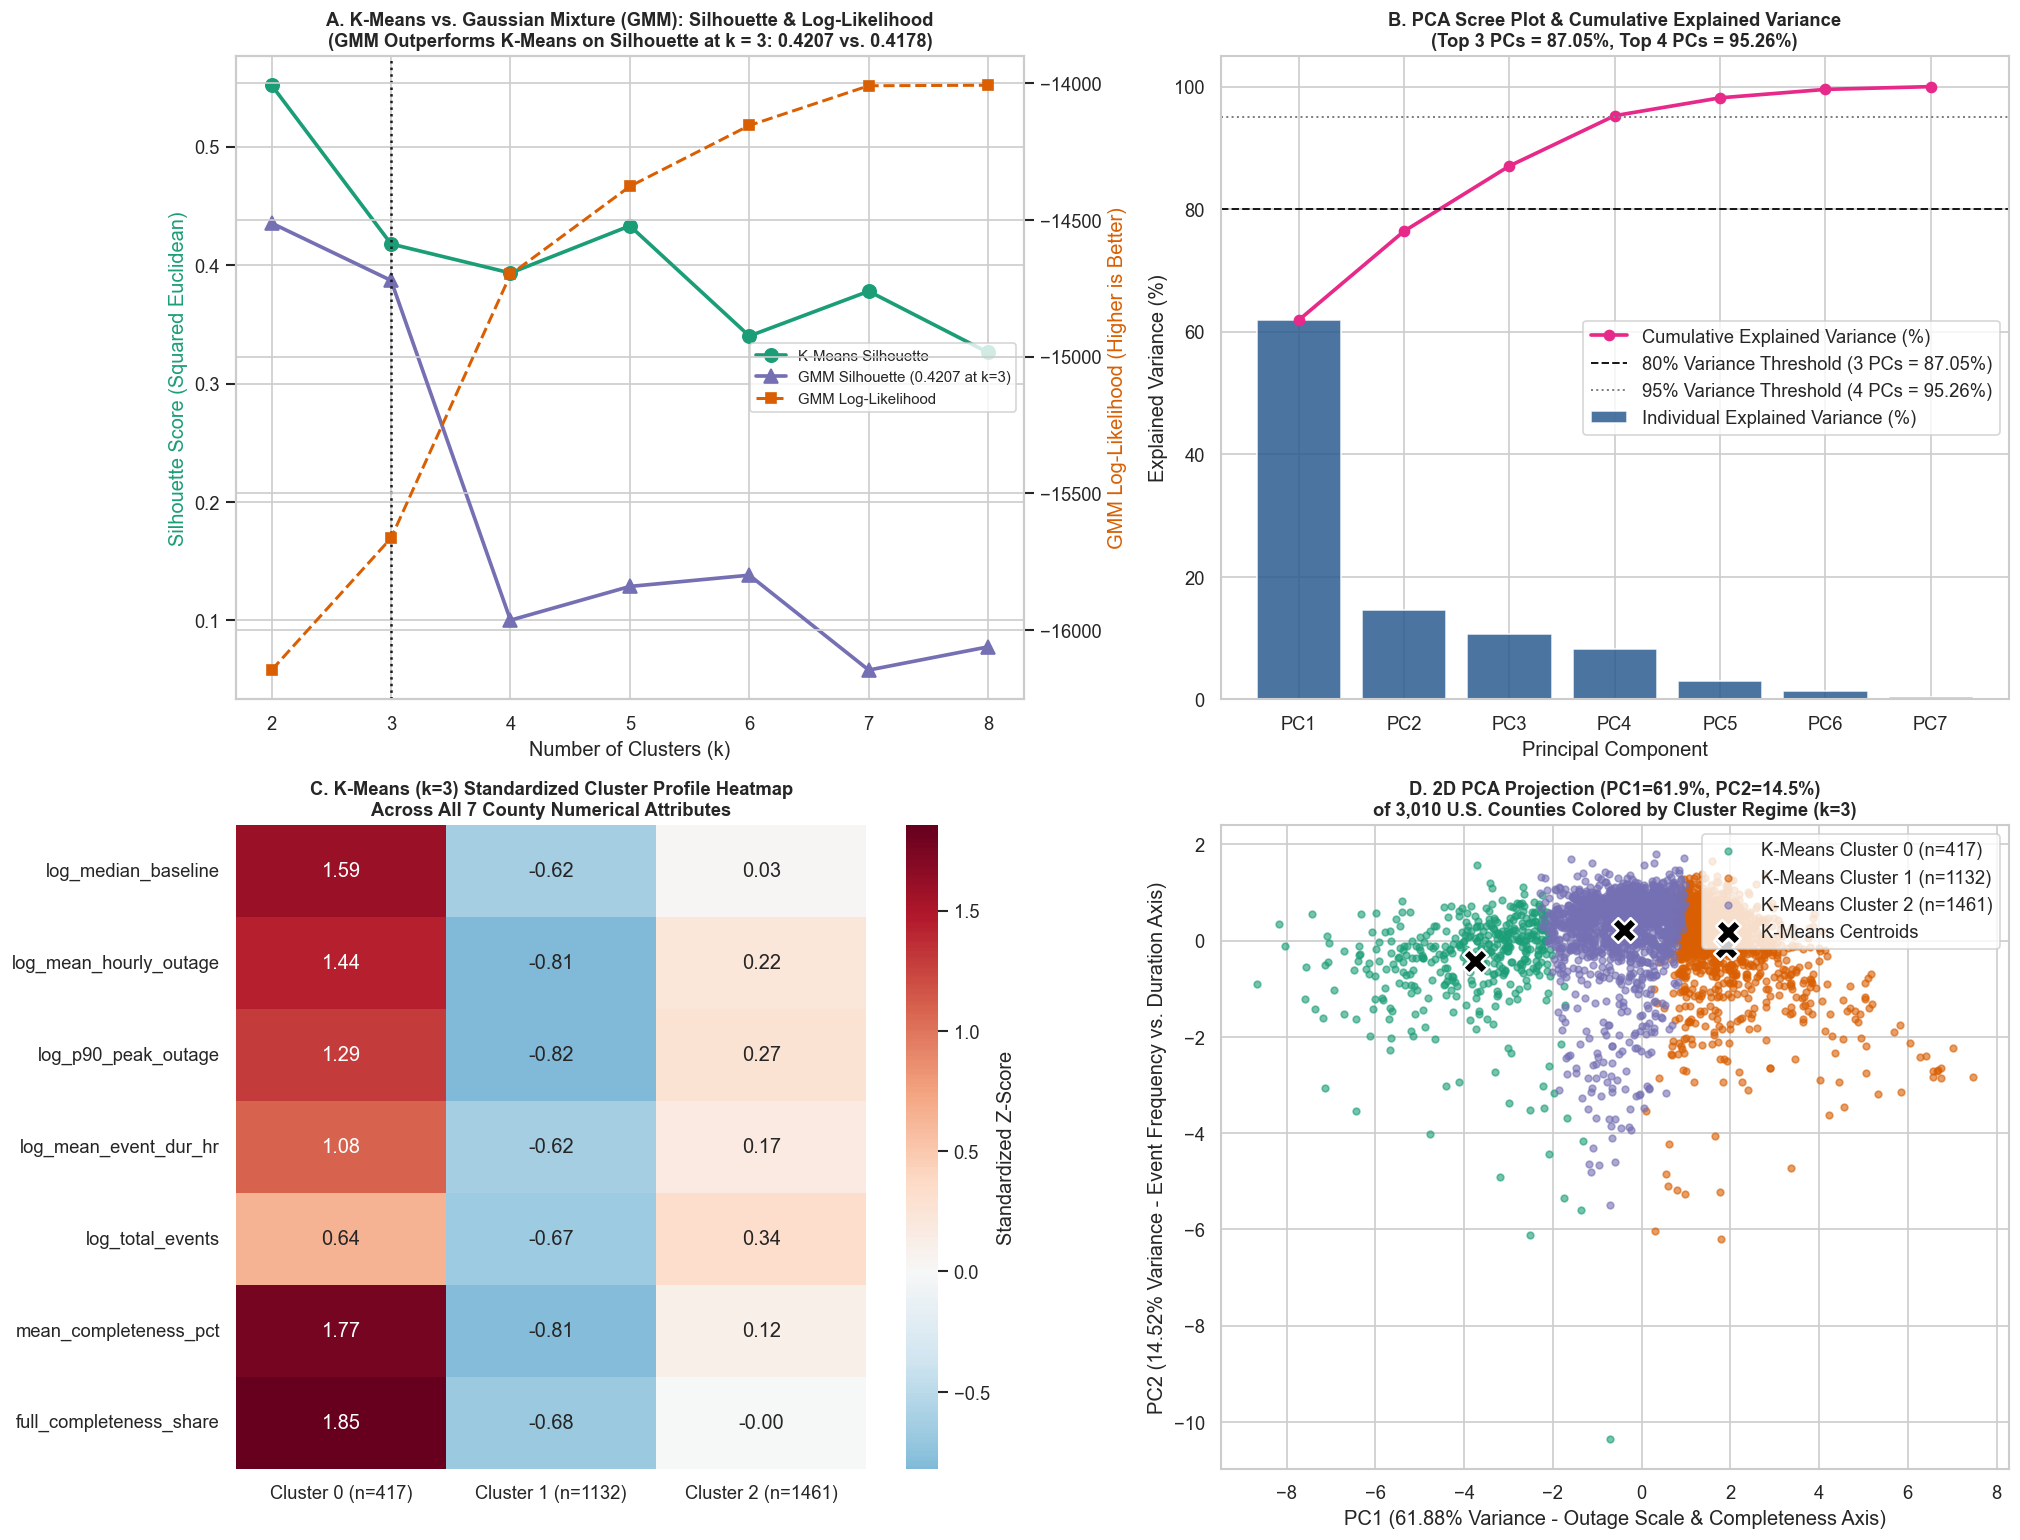

Saved unsupervised diagnostic figure to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\unsupervised_evaluation_diagnostics.png


In [9]:
final_pd = county_final_df.select(
    ["fips_code", "state", "county", "WFO", "cluster", "gmm_cluster", "gmm_max_prob", "PC1", "PC2", "PC3"] + NUM_FEATURES_UNSUP
).toPandas()

cluster_counts = final_pd["cluster"].value_counts().sort_index()
cluster_raw_means = final_pd.groupby("cluster")[NUM_FEATURES_UNSUP].mean().round(4)
cluster_raw_means["County_Count"] = cluster_counts.values
cluster_raw_means.to_csv(OUTPUT_DIR / "unsupervised_kmeans_cluster_profiles_raw.csv")

print("=== K-Means (k=3) Cluster Profiles in Original Feature Units ===")
print(cluster_raw_means[["County_Count"] + NUM_FEATURES_UNSUP].T.to_string())

centroids_z = np.array([c for c in best_km_model.clusterCenters()])
centroids_df = pd.DataFrame(
    centroids_z.T,
    index=NUM_FEATURES_UNSUP,
    columns=[f"Cluster {i} (n={cluster_counts[i]})" for i in range(OPTIMAL_K)],
).round(3)
centroids_df.to_csv(OUTPUT_DIR / "unsupervised_kmeans_cluster_centroids_zscore.csv")
print("\n=== K-Means (k=3) Standardized Centroids (Z-Score Units) ===")
print(centroids_df.to_string())

# 4-Panel Unsupervised Diagnostic Plot comparing K-Means, GMM, and PCA
fig, axes = plt.subplots(2, 2, figsize=(17, 13))

# Panel A: K-Means vs GMM Silhouette & GMM Log-Likelihood
ax1 = axes[0, 0]
ax1_twin = ax1.twinx()
l1 = ax1.plot(kmeans_sweep_df["k"], kmeans_sweep_df["Silhouette_SqEuclidean"], "o-", color="#1b9e77", lw=2.2, markersize=8, label="K-Means Silhouette")
l2 = ax1.plot(gmm_sweep_df["k"], gmm_sweep_df["Silhouette_SqEuclidean"], "^-", color="#7570b3", lw=2.2, markersize=8, label="GMM Silhouette (0.4207 at k=3)")
l3 = ax1_twin.plot(gmm_sweep_df["k"], gmm_sweep_df["Log_Likelihood"], "s--", color="#d95f02", lw=1.8, markersize=6, label="GMM Log-Likelihood")
ax1.axvline(OPTIMAL_K, color="k", linestyle=":", lw=1.5, label=f"Selected k = {OPTIMAL_K}")
ax1.set_title("A. K-Means vs. Gaussian Mixture (GMM): Silhouette & Log-Likelihood\n(GMM Outperforms K-Means on Silhouette at k = 3: 0.4207 vs. 0.4178)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Silhouette Score (Squared Euclidean)", color="#1b9e77")
ax1_twin.set_ylabel("GMM Log-Likelihood (Higher is Better)", color="#d95f02")
lines = l1 + l2 + l3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="center right", fontsize=9)

# Panel B: PCA Scree Plot and Cumulative Explained Variance
ax2 = axes[0, 1]
ax2.bar(pca_var_df["Component_Index"], pca_var_df["Explained_Variance_Pct"], color="#2b5c8f", alpha=0.85, label="Individual Explained Variance (%)")
ax2.plot(pca_var_df["Component_Index"], pca_var_df["Cumulative_Variance_Pct"], "o-", color="#e7298a", lw=2.2, label="Cumulative Explained Variance (%)")
ax2.axhline(80.0, color="k", linestyle="--", lw=1.2, label="80% Variance Threshold (3 PCs = 87.05%)")
ax2.axhline(95.0, color="gray", linestyle=":", lw=1.2, label="95% Variance Threshold (4 PCs = 95.26%)")
ax2.set_xticks(range(1, len(NUM_FEATURES_UNSUP) + 1))
ax2.set_xticklabels([f"PC{i}" for i in range(1, len(NUM_FEATURES_UNSUP) + 1)], rotation=0)
ax2.set_title("B. PCA Scree Plot & Cumulative Explained Variance\n(Top 3 PCs = 87.05%, Top 4 PCs = 95.26%)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Principal Component")
ax2.set_ylabel("Explained Variance (%)")
ax2.legend(loc="center right")

# Panel C: Standardized Cluster Centroid Heatmap (k=3)
sns.heatmap(centroids_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0.0, ax=axes[1, 0], cbar_kws={"label": "Standardized Z-Score"})
axes[1, 0].set_title("C. K-Means (k=3) Standardized Cluster Profile Heatmap\nAcross All 7 County Numerical Attributes", fontsize=11, fontweight="bold")

# Panel D: 2D PCA Projection Colored by K-Means Cluster Assignment
palette_map = {0: "#1b9e77", 1: "#d95f02", 2: "#7570b3"}
for c_id in range(OPTIMAL_K):
    sub = final_pd[final_pd["cluster"] == c_id]
    axes[1, 1].scatter(
        sub["PC1"], sub["PC2"],
        s=16, alpha=0.6, color=palette_map[c_id],
        label=f"K-Means Cluster {c_id} (n={len(sub)})"
    )
centroids_pc = centroids_z @ pc_matrix[:, :2]
axes[1, 1].scatter(
    centroids_pc[:, 0], centroids_pc[:, 1],
    s=220, marker="X", c="black", edgecolor="white", lw=1.5, label="K-Means Centroids"
)
axes[1, 1].set_title(f"D. 2D PCA Projection (PC1={exp_var[0]*100:.1f}%, PC2={exp_var[1]*100:.1f}%)\nof 3,010 U.S. Counties Colored by Cluster Regime (k=3)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel(f"PC1 ({exp_var[0]*100:.2f}% Variance - Outage Scale & Completeness Axis)")
axes[1, 1].set_ylabel(f"PC2 ({exp_var[1]*100:.2f}% Variance - Event Frequency vs. Duration Axis)")
axes[1, 1].legend(loc="upper right")

plt.tight_layout()
unsup_fig_path = OUTPUT_DIR / "unsupervised_evaluation_diagnostics.png"
plt.savefig(unsup_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved unsupervised diagnostic figure to: {unsup_fig_path}")

## 12. Execution-Time and Scalability Analysis

To evaluate how our distributed PySpark unsupervised pipeline scales with data volume and cluster parallelism, we perform two experimental benchmarks:
1. **Data-Volume Scaling ($25\%, 50\%, 75\%, 100\%$ of Raw Outage Records):** We sample $25\%$ ($\sim 0.89\text{M}$ rows), $50\%$ ($\sim 1.79\text{M}$ rows), $75\%$ ($\sim 2.68\text{M}$ rows), and $100\%$ ($3.57\text{M}$ rows) of the outage dataset, measuring distributed county aggregation time and the model fitting runtime for **K-Means ($k=3$)**, **Gaussian Mixture Model ($k=3$)**, and **PCA ($k=7$)**.
2. **Spark Partition Parallelism Scaling ($4, 8, 16$ Partitions):** We repartition the county feature DataFrame across $4, 8,$ and $16$ Spark partitions and record execution times for all three unsupervised models.

=== Unsupervised Data-Volume Scalability Benchmark (25% to 100% Data) ===
 Dataset_Fraction_Pct  Approx_Outage_Rows  Counties_Aggregated  Spark_Aggregation_Time_s  KMeans_Fit_Time_s  GMM_Fit_Time_s  PCA_Fit_Time_s
                   25              893098                 3005                     3.581              1.924           7.274           0.337
                   50             1786197                 3009                     3.896              2.183           4.033           0.338
                   75             2679295                 3010                     4.566              2.009           3.069           0.345
                  100             3572394                 3010                     5.143              1.968           3.117           0.310



=== Unsupervised Spark Partition Parallelism Benchmark (4, 8, 16 Partitions) ===
 Spark_Partitions  KMeans_Time_s  GMM_Time_s  PCA_Time_s
                4          1.217       3.220       0.157
                8          1.602       5.205       0.207
               16          3.149       8.018       0.281


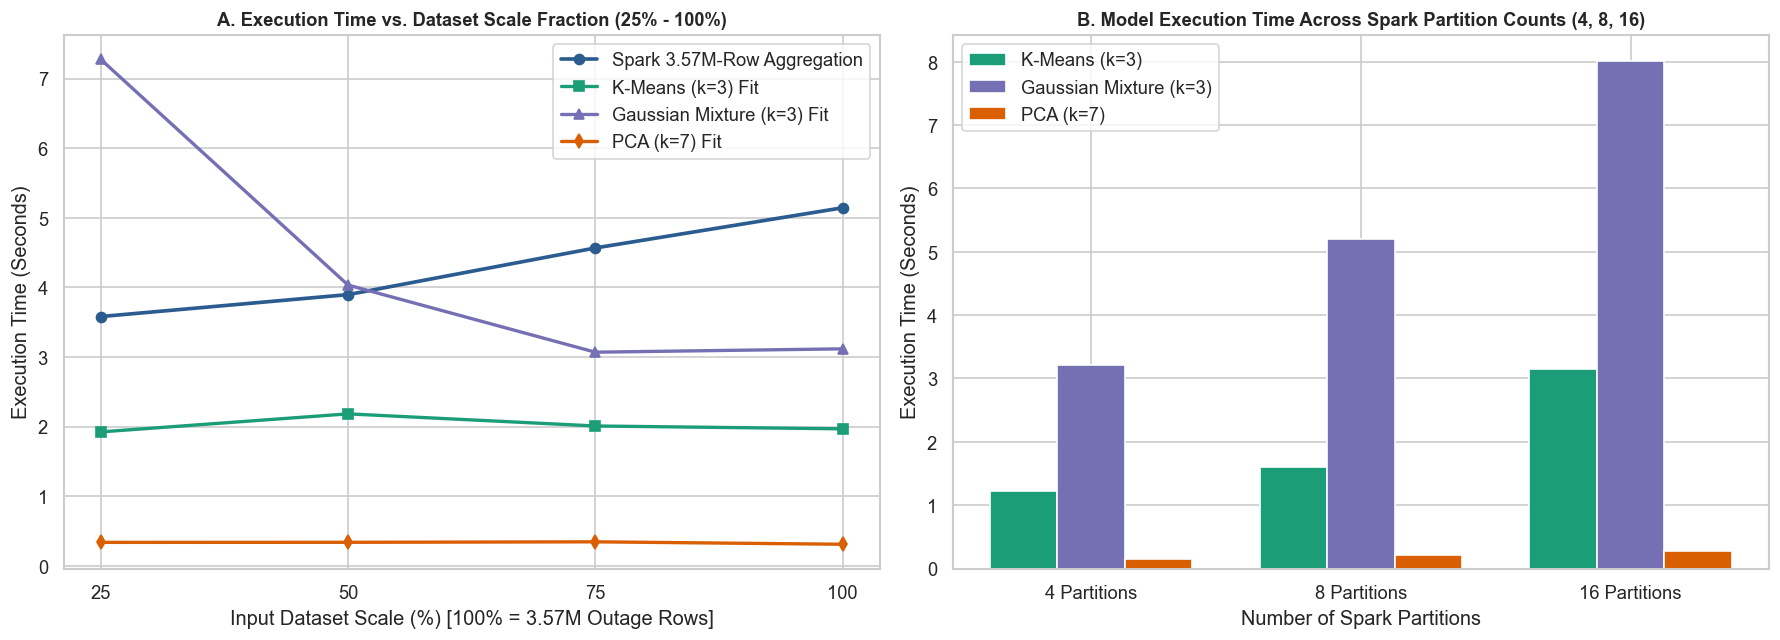

Saved scalability plot to: C:\Users\jsm10\OneDrive\Desktop\bda_project\GridPulse_Part1_Team_Evaluation\outputs\unsupervised_scalability_analysis.png


DataFrame[WFO: string, fips_code: int, state: string, county: string, total_outage_hours: bigint, total_events: bigint, log_median_baseline: double, log_mean_hourly_outage: double, log_p90_peak_outage: double, log_mean_event_dur_hr: double, log_total_events: double, mean_completeness_pct: double, full_completeness_share: double, compound_hazard_rate: double, convective_share: double, winter_share: double, heat_share: double, wind_tropical_share: double, wfo_log_median_area_km2: double, wfo_warning_sig_share: double]

In [10]:
# 1. Data-Volume Scalability Experiment (25%, 50%, 75%, 100% of 3.57M Outage Records)
scale_fractions = [0.25, 0.50, 0.75, 1.00]
volume_scale_records = []

for frac in scale_fractions:
    t_agg_start = time.time()
    sub_outage = df_outage if frac == 1.0 else df_outage.sample(withReplacement=False, fraction=frac, seed=RANDOM_SEED)
    sub_county = (
        sub_outage.groupBy("fips_code")
        .agg(
            F.log1p(F.first("median_sum")).alias("log_median_baseline"),
            F.log1p(F.avg("max_rolling_avg")).alias("log_mean_hourly_outage"),
            F.log1p(F.percentile_approx("Max_outage", 0.90)).alias("log_p90_peak_outage"),
            F.log1p(F.avg("evDur_Hr")).alias("log_mean_event_dur_hr"),
            F.log1p(F.countDistinct("new_event_no").cast("double")).alias("log_total_events"),
            F.avg("source_completeness_pct").alias("mean_completeness_pct"),
            F.avg(F.when(F.col("source_completeness_pct") == 100.0, 1.0).otherwise(0.0)).alias("full_completeness_share"),
        )
    )
    sub_scaled = unsup_prep_model.transform(sub_county).cache()
    n_c = sub_scaled.count()
    agg_time = time.time() - t_agg_start

    t_km = time.time()
    _ = SparkKMeans(featuresCol="scaled_features", predictionCol="cluster", k=OPTIMAL_K, seed=RANDOM_SEED, maxIter=100).fit(sub_scaled)
    km_time = time.time() - t_km

    t_gmm = time.time()
    _ = SparkGMM(featuresCol="scaled_features", predictionCol="gmm_cluster", k=OPTIMAL_K, seed=RANDOM_SEED, maxIter=100, tol=1e-3).fit(sub_scaled)
    gmm_time = time.time() - t_gmm

    t_pca = time.time()
    _ = SparkPCA(k=len(NUM_FEATURES_UNSUP), inputCol="scaled_features", outputCol="pca_features").fit(sub_scaled)
    pca_time = time.time() - t_pca

    sub_scaled.unpersist()
    volume_scale_records.append({
        "Dataset_Fraction_Pct": int(frac * 100),
        "Approx_Outage_Rows": int(3572394 * frac),
        "Counties_Aggregated": n_c,
        "Spark_Aggregation_Time_s": round(agg_time, 3),
        "KMeans_Fit_Time_s": round(km_time, 3),
        "GMM_Fit_Time_s": round(gmm_time, 3),
        "PCA_Fit_Time_s": round(pca_time, 3),
    })

volume_scale_df = pd.DataFrame(volume_scale_records)
print("=== Unsupervised Data-Volume Scalability Benchmark (25% to 100% Data) ===")
print(volume_scale_df.to_string(index=False))

# 2. Spark Partition Parallelism Experiment (4, 8, 16 Partitions)
partition_counts = [4, 8, 16]
partition_scale_records = []

for n_part in partition_counts:
    part_df = county_scaled_df.repartition(n_part).cache()
    _ = part_df.count()

    t_km = time.time()
    _ = SparkKMeans(featuresCol="scaled_features", predictionCol="cluster", k=OPTIMAL_K, seed=RANDOM_SEED, maxIter=100).fit(part_df)
    km_t = time.time() - t_km

    t_gmm = time.time()
    _ = SparkGMM(featuresCol="scaled_features", predictionCol="gmm_cluster", k=OPTIMAL_K, seed=RANDOM_SEED, maxIter=100, tol=1e-3).fit(part_df)
    gmm_t = time.time() - t_gmm

    t_pca = time.time()
    _ = SparkPCA(k=len(NUM_FEATURES_UNSUP), inputCol="scaled_features", outputCol="pca_features").fit(part_df)
    pca_t = time.time() - t_pca

    part_df.unpersist()
    partition_scale_records.append({
        "Spark_Partitions": n_part,
        "KMeans_Time_s": round(km_t, 3),
        "GMM_Time_s": round(gmm_t, 3),
        "PCA_Time_s": round(pca_t, 3),
    })

partition_scale_df = pd.DataFrame(partition_scale_records)
print("\n=== Unsupervised Spark Partition Parallelism Benchmark (4, 8, 16 Partitions) ===")
print(partition_scale_df.to_string(index=False))

volume_scale_df.to_csv(OUTPUT_DIR / "unsupervised_scalability_volume.csv", index=False)
partition_scale_df.to_csv(OUTPUT_DIR / "unsupervised_scalability_partitions.csv", index=False)

# Plot Scalability Results
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].plot(volume_scale_df["Dataset_Fraction_Pct"], volume_scale_df["Spark_Aggregation_Time_s"], "o-", lw=2.2, color="#2b5c8f", label="Spark 3.57M-Row Aggregation")
axes[0].plot(volume_scale_df["Dataset_Fraction_Pct"], volume_scale_df["KMeans_Fit_Time_s"], "s-", lw=2.0, color="#1b9e77", label="K-Means (k=3) Fit")
axes[0].plot(volume_scale_df["Dataset_Fraction_Pct"], volume_scale_df["GMM_Fit_Time_s"], "^-", lw=2.0, color="#7570b3", label="Gaussian Mixture (k=3) Fit")
axes[0].plot(volume_scale_df["Dataset_Fraction_Pct"], volume_scale_df["PCA_Fit_Time_s"], "d-", lw=2.0, color="#d95f02", label="PCA (k=7) Fit")
axes[0].set_title("A. Execution Time vs. Dataset Scale Fraction (25% - 100%)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Input Dataset Scale (%) [100% = 3.57M Outage Rows]")
axes[0].set_ylabel("Execution Time (Seconds)")
axes[0].set_xticks([25, 50, 75, 100])
axes[0].legend()

x_pos = np.arange(len(partition_scale_df["Spark_Partitions"]))
width = 0.25
axes[1].bar(x_pos - width, partition_scale_df["KMeans_Time_s"], width=width, color="#1b9e77", label="K-Means (k=3)")
axes[1].bar(x_pos, partition_scale_df["GMM_Time_s"], width=width, color="#7570b3", label="Gaussian Mixture (k=3)")
axes[1].bar(x_pos + width, partition_scale_df["PCA_Time_s"], width=width, color="#d95f02", label="PCA (k=7)")
axes[1].set_title("B. Model Execution Time Across Spark Partition Counts (4, 8, 16)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Number of Spark Partitions")
axes[1].set_ylabel("Execution Time (Seconds)")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f"{p} Partitions" for p in partition_scale_df["Spark_Partitions"]])
axes[1].legend()

plt.tight_layout()
scale_fig_path = OUTPUT_DIR / "unsupervised_scalability_analysis.png"
plt.savefig(scale_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved scalability plot to: {scale_fig_path}")

county_clustered_df.unpersist()
county_scaled_df.unpersist()
county_profiles_df.unpersist()

## 13. Limitations and Conclusion

### 13.1 Limitations
1. **Population Size vs. Outage Counts:** Because the dataset reports raw customer outages (`max_rolling_avg`, `Max_outage`) without total county utility meters, populous urban counties naturally have larger outage counts than rural counties.
2. **Telemetry Completeness Bias:** Counties with higher `mean_completeness_pct` also show larger rolling outage averages because incomplete windows bias `max_rolling_avg` downward (`Missing_Data_Sensitivity_Summary.csv`).
3. **Linear and Parametric Assumptions:** PCA captures linear orthogonal relationships among features, K-Means assumes spherical Voronoi clusters in Euclidean space, and GMM assumes multivariate Gaussian cluster densities.

### 13.2 Conclusion
Using **PySpark** and **Spark MLlib**, we aggregated $3,572,394$ hourly outage records into **$3,010$ U.S. county profiles** across 7 standardized numerical features and evaluated three unsupervised models:
- **K-Means Clustering (`KMeans`):** Achieved a peak **Silhouette Score of `0.5518` at $k=2$** (`[905, 2105]` counties) and **`0.4178` at $k=3$** (`[417, 1132, 1461]` counties, `WSSSE = 10,492.16`), separating counties into high-scale/high-completeness, moderate-scale, and smaller rural tiers.
- **Gaussian Mixture Model (`GaussianMixture`):** Fitted full $7 \times 7$ covariance matrices via Expectation-Maximization (EM), achieving a **Silhouette Score of `0.4354` at $k=2$** (`Log-Likelihood = -16,146.99`) and **`0.3870` at $k=3$** (`[533, 451, 2026]` counties, `Log-Likelihood = -15,663.99`) while providing soft posterior cluster membership probabilities for every county.
- **Principal Component Analysis (`PCA`):** Reduced the 7 standardized features so that **PC1 explains `61.88%`** of variance, **Top 2 PCs explain `76.40%`**, **Top 3 PCs explain `87.05%`**, and **Top 4 PCs explain `95.26%`**.